In [1]:
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense,Dropout,MaxPool2D,GlobalAveragePooling2D
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report,confusion_matrix
from tensorflow.keras.models import load_model

I0000 00:00:1793631371.475619   15634 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793631372.158170   15634 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793631375.115781   15634 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
training_path = "../Datasets/data/train/Medical/X-Ray/chest x-ray/train"
testing_path = "../Datasets/data/test/Medical/X-Ray/chest x-ray/test"
valid_path = "../Datasets/data/vaild/Medical/X-Ray/chest x-ray/val"

In [3]:
train_dataug = ImageDataGenerator(
    preprocessing_function = preprocess_input,
    rotation_range = 10,
    zoom_range = 0.2,
    horizontal_flip = True
)
test_dataug = ImageDataGenerator(
    preprocessing_function = preprocess_input
)
valid_dataug = ImageDataGenerator(
    preprocessing_function = preprocess_input
)

In [10]:
training_set = train_dataug.flow_from_directory(
    training_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary",
    shuffle = False
)
valid_set = valid_dataug.flow_from_directory(
    valid_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary"
)
testing_set = test_dataug.flow_from_directory(
    testing_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary",
    shuffle = False
)

Found 8075 images belonging to 2 classes.
Found 1006 images belonging to 2 classes.
Found 1550 images belonging to 2 classes.


In [5]:
base_model = EfficientNetV2B0(weights="imagenet",include_top=False,input_shape=(224,224,3))

I0000 00:00:1793589154.752031    1060 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [6]:
base_model.trainable = False

In [7]:
base_model.output

<KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_269>

In [8]:
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256,activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(512, activation="relu")(x)
x = Dropout(0.3)(x)
x = Dense(256, activation='relu')(x)
output = Dense(1,activation="sigmoid")(x)

In [9]:
model = Model(inputs = base_model.input,outputs = output)

In [10]:
model.compile(optimizer=Adam(learning_rate=0.001),metrics=["accuracy"],loss="binary_crossentropy")

In [11]:
early_stop = EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)

In [12]:
history = model.fit(training_set,validation_data=(valid_set),epochs=20,callbacks=[early_stop])

Epoch 1/20


I0000 00:00:1793589159.816298    1060 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793589169.869311    2060 service.cc:153] XLA service 0x706aac0378c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793589169.869370    2060 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1793589170.359485    2060 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793589173.214271    2060 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1793589174.519102    2060 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_19149__.265
I0000 00:00:1793589209.710673    2060 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 64/505 ━━━━━━━━━━━━━━━━━━━━ 2:52 392ms/step - accuracy: 0.6826 - loss: 0.5687

I0000 00:00:1793589239.051778    2057 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_19149__.265


505/505 ━━━━━━━━━━━━━━━━━━━━ 313s 520ms/step - accuracy: 0.8717 - loss: 0.2964 - val_accuracy: 0.9284 - val_loss: 0.1602
Epoch 2/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 180s 356ms/step - accuracy: 0.9181 - loss: 0.2102 - val_accuracy: 0.9652 - val_loss: 0.1046
Epoch 3/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 165s 327ms/step - accuracy: 0.9313 - loss: 0.1824 - val_accuracy: 0.9682 - val_loss: 0.0998
Epoch 4/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 175s 347ms/step - accuracy: 0.9340 - loss: 0.1799 - val_accuracy: 0.9672 - val_loss: 0.0886
Epoch 5/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 150s 297ms/step - accuracy: 0.9367 - loss: 0.1630 - val_accuracy: 0.9533 - val_loss: 0.1246
Epoch 6/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 141s 279ms/step - accuracy: 0.9413 - loss: 0.1594 - val_accuracy: 0.9602 - val_loss: 0.0968
Epoch 7/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 151s 298ms/step - accuracy: 0.9428 - loss: 0.1506 - val_accuracy: 0.9672 - val_loss: 0.0889
Epoch 8/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 148s 294ms/step - accuracy: 0.9443 - loss: 0.14

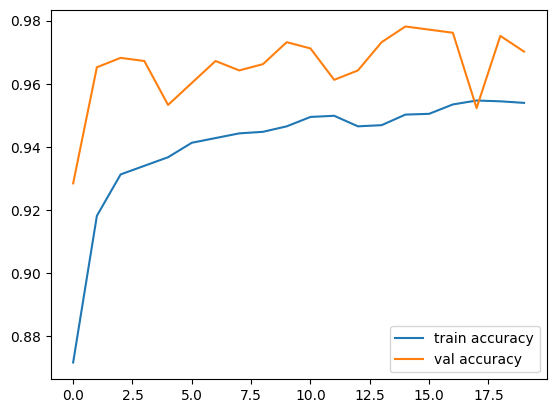

In [13]:
plt.plot(history.history['accuracy'],label = "train accuracy")
plt.plot(history.history['val_accuracy'],label = "val accuracy")
plt.legend()
plt.show()

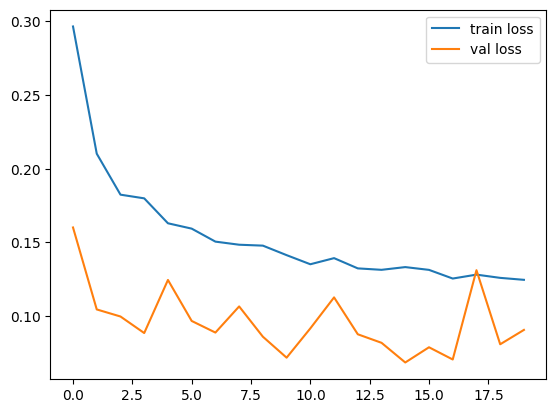

In [14]:
plt.plot(history.history['loss'],label = "train loss")
plt.plot(history.history['val_loss'],label = "val loss")
plt.legend()
plt.show()

In [15]:
prediction = model.predict(testing_set)
training_set.class_indices 

97/97 ━━━━━━━━━━━━━━━━━━━━ 37s 230ms/step


{'ABNORMAL': 0, 'NORMAL': 1}

In [16]:
true_prediction = (prediction >= 0.5).astype(int)

In [17]:
y_true = testing_set.classes

              precision    recall  f1-score   support

           0       0.98      0.96      0.97       800
           1       0.96      0.98      0.97       750

    accuracy                           0.97      1550
   macro avg       0.97      0.97      0.97      1550
weighted avg       0.97      0.97      0.97      1550



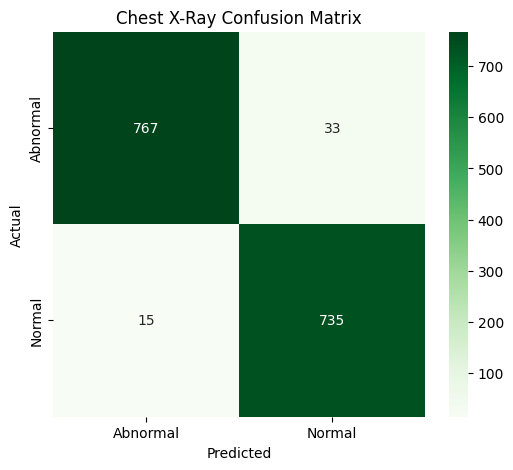

In [28]:
print(classification_report(y_true,true_prediction))
import seaborn as sns

cm = confusion_matrix(
    y_true,
    true_prediction.ravel()
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Abnormal', 'Normal'],
    yticklabels=['Abnormal', 'Normal']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Chest X-Ray Confusion Matrix")

plt.show()

In [19]:
# model.save("chest_x_ray_model.keras")
model1 = model

In [5]:
model = load_model("../models/chest_x_ray_model.keras")

I0000 00:00:1793631396.652929   15634 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [6]:
train_true = training_set.classes
train_prob = model.predict(training_set)

I0000 00:00:1793631402.164597   15634 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793631403.825888   16499 service.cc:153] XLA service 0x738938034c10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793631403.825931   16499 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1793631403.994615   16499 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793631404.796162   16499 cuda_dnn.cc:461] Loaded cuDNN version 92400


  1/505 ━━━━━━━━━━━━━━━━━━━━ 2:19:44 17s/step

I0000 00:00:1793631418.582673   16499 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


505/505 ━━━━━━━━━━━━━━━━━━━━ 162s 288ms/step


In [7]:
trian_pred = (train_prob >= 0.5).astype(int)

In [11]:
training_set.shuffle = False

training_set.reset()

train_true = training_set.classes

train_prob = model.predict(training_set)

train_pred = (train_prob.ravel() >= 0.5).astype(int)

print(classification_report(train_true, train_pred))

print(confusion_matrix(train_true, train_pred))

505/505 ━━━━━━━━━━━━━━━━━━━━ 118s 233ms/step
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      4228
           1       0.96      0.98      0.97      3847

    accuracy                           0.97      8075
   macro avg       0.97      0.97      0.97      8075
weighted avg       0.97      0.97      0.97      8075

[[4051  177]
 [  86 3761]]


In [21]:
image_path = "../Datasets/normal.jpg"
prediction = image.load_img(image_path,target_size = (224,224))
prediction = image.img_to_array(prediction)

In [22]:
import numpy as np

In [23]:
prediction = np.expand_dims(prediction,axis=0)
prediction.shape

(1, 224, 224, 3)

In [24]:
prediction = preprocess_input(prediction)

In [25]:
pred_data = model.predict(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step


In [26]:
(pred_data >= 0.5).astype(int)

array([[1]])

Model loaded successfully!
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 1)
Last convolutional layer: top_conv

========== PREDICTION ==========
Normal probability: 55.01040816307068 %
Abnormal probability: 44.98959183692932 %
Predicted class: 1
Prediction: Normal
Confidence: 55.01040816307068 %


/home/kripank/Projects/fast API/env/lib/python3.10/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)



Normal Grad-CAM generated!
Abnormal Grad-CAM generated!


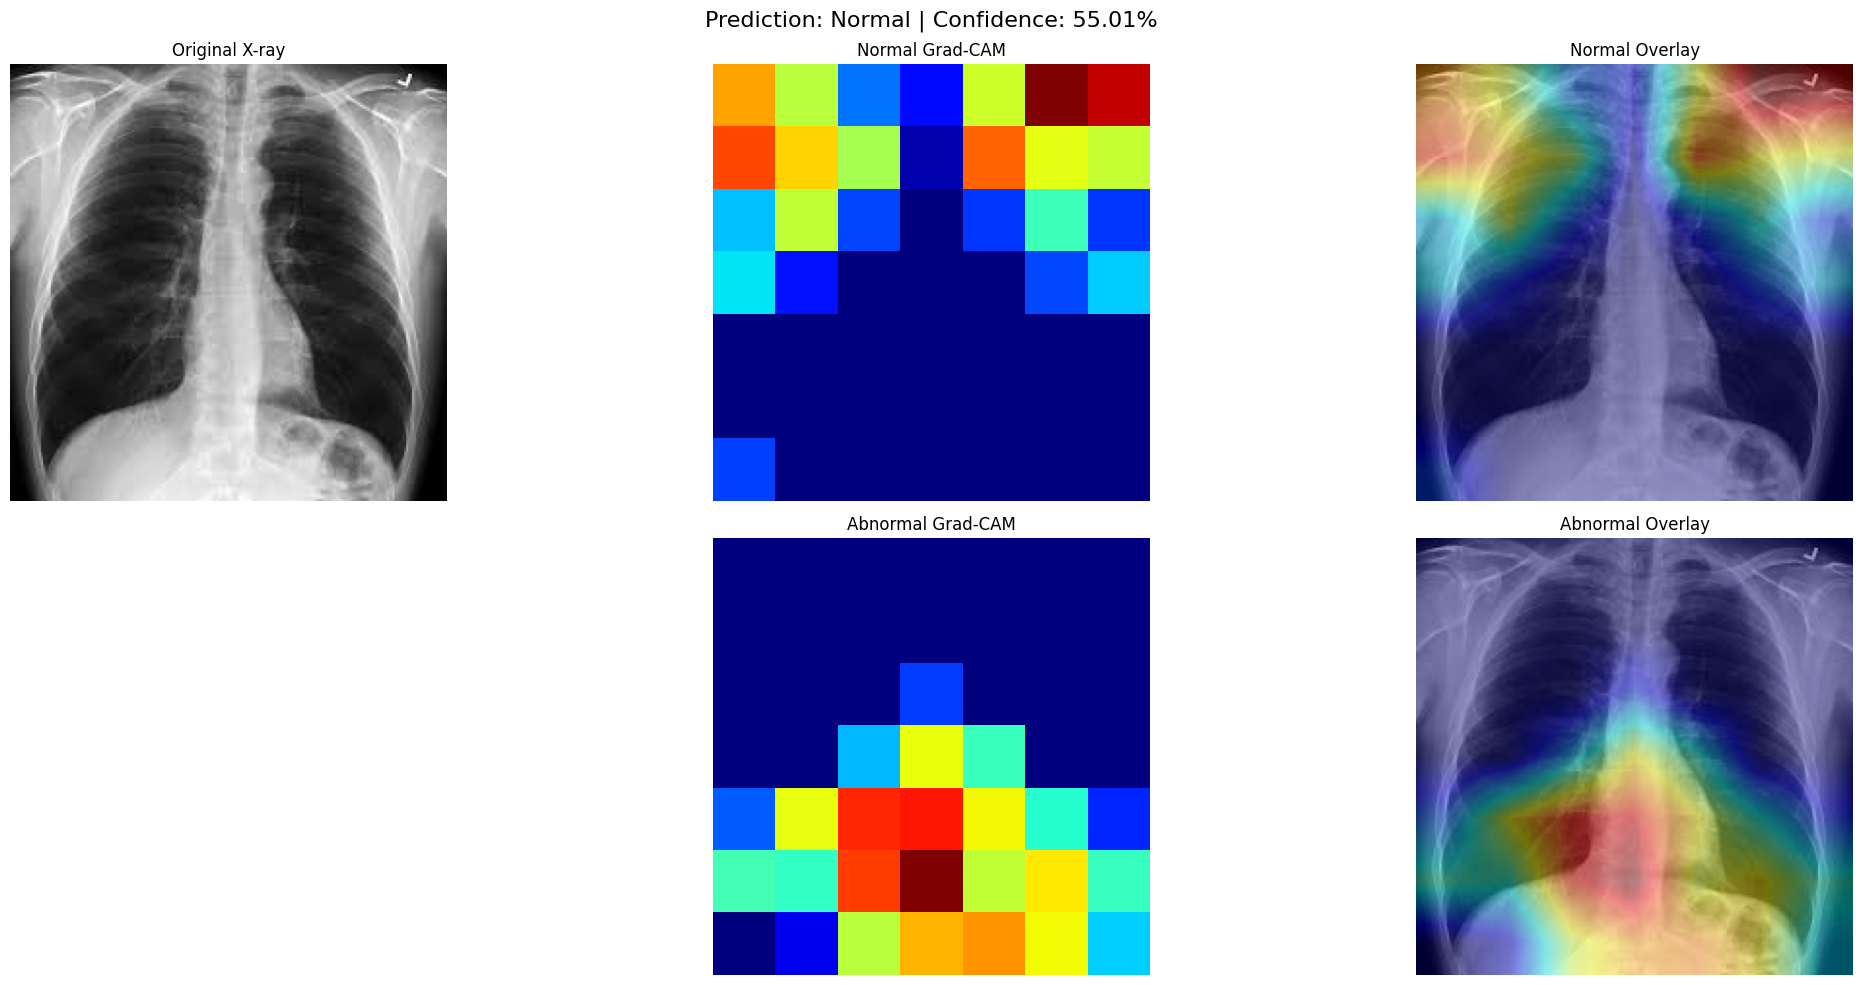

In [27]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model


# --------------------------------------------------
# STEP 1: Load the trained model
# --------------------------------------------------

# model_path = "../models/chest_x_ray_model.keras"

# model = load_model(model_path)

print("Model loaded successfully!")
print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)


# --------------------------------------------------
# STEP 2: Load and preprocess the image
# --------------------------------------------------

image_path = "../Datasets/normal.jpg"

# Read the original image
original = cv2.imread(image_path)

if original is None:
    raise FileNotFoundError("Image not found!")

# Convert BGR to RGB
original_rgb = cv2.cvtColor(
    original,
    cv2.COLOR_BGR2RGB
)

# Resize image
image = cv2.resize(
    original_rgb,
    (224, 224)
)

# Preprocessing
# Use this only if it matches your training pipeline.
image = preprocess_input(image)

# Add batch dimension
input_image = np.expand_dims(
    image,
    axis=0
)


# ==================================================
# STEP 3: FIND LAST CONVOLUTIONAL LAYER
# ==================================================

last_conv_layer_name = "top_conv"

last_conv_layer = model.get_layer(
    last_conv_layer_name
)

print("Last convolutional layer:", last_conv_layer_name)


# ==================================================
# STEP 4: CREATE GRAD-CAM MODEL
# ==================================================

grad_model = tf.keras.Model(
    inputs=model.inputs,

    outputs=[
        last_conv_layer.output,
        model.output
    ]
)


# ==================================================
# STEP 5: PREDICTION
# ==================================================

predictions = model.predict(
    input_image,
    verbose=0
)

normal_probability = float(predictions[0][0])

abnormal_probability = 1.0 - normal_probability

if normal_probability >= 0.5:

    predicted_class = 1

    predicted_label = "Normal"

    confidence = normal_probability

else:

    predicted_class = 0

    predicted_label = "Abnormal"

    confidence = abnormal_probability


print("\n========== PREDICTION ==========")

print("Normal probability:", normal_probability * 100, "%")

print("Abnormal probability:", abnormal_probability * 100, "%")

print("Predicted class:", predicted_class)

print("Prediction:", predicted_label)

print("Confidence:", confidence * 100, "%")


# ==================================================
# STEP 6: GRAD-CAM FUNCTION
# ==================================================

def generate_gradcam(input_image, target_class):

    with tf.GradientTape() as tape:

        feature_maps, predictions = grad_model(
            input_image,
            training=False
        )

        # Class 0 = Abnormal
        # Class 1 = Normal

        normal_score = predictions[:, 0]

        if target_class == 0:

            score = 1.0 - normal_score

        else:

            score = normal_score

    # Calculate gradients
    gradients = tape.gradient(
        score,
        feature_maps
    )

    if gradients is None:

        raise ValueError(
            "Gradients could not be calculated!"
        )

    # Calculate average gradient weights
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    # Remove batch dimension
    feature_maps = feature_maps[0]

    weights = weights[0]

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        feature_maps * weights[tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    # Keep positive activations
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize
    max_value = tf.reduce_max(heatmap)

    heatmap = heatmap / (
        max_value + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()


# ==================================================
# STEP 7: GENERATE NORMAL GRAD-CAM
# ==================================================

normal_heatmap = generate_gradcam(
    input_image,
    target_class=1
)

print("\nNormal Grad-CAM generated!")


# ==================================================
# STEP 8: GENERATE ABNORMAL GRAD-CAM
# ==================================================

abnormal_heatmap = generate_gradcam(
    input_image,
    target_class=0
)

print("Abnormal Grad-CAM generated!")


# ==================================================
# STEP 9: CREATE HEATMAP OVERLAY FUNCTION
# ==================================================

def create_overlay(original_image, heatmap):

    # Resize heatmap to original image dimensions
    heatmap = cv2.resize(
        heatmap,
        (
            original_image.shape[1],
            original_image.shape[0]
        )
    )

    # Convert heatmap to 0-255
    heatmap = np.uint8(
        255 * heatmap
    )

    # Apply color map
    colored_heatmap = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    # Convert BGR to RGB
    colored_heatmap = cv2.cvtColor(
        colored_heatmap,
        cv2.COLOR_BGR2RGB
    )

    # Combine original image and heatmap
    overlay = cv2.addWeighted(
        original_image,
        0.6,
        colored_heatmap,
        0.4,
        0
    )

    return colored_heatmap, overlay


# ==================================================
# STEP 10: CREATE NORMAL OVERLAY
# ==================================================

normal_colored, normal_overlay = create_overlay(
    original_rgb,
    normal_heatmap
)


# ==================================================
# STEP 11: CREATE ABNORMAL OVERLAY
# ==================================================

abnormal_colored, abnormal_overlay = create_overlay(
    original_rgb,
    abnormal_heatmap
)


# ==================================================
# STEP 12: DISPLAY ALL RESULTS
# ==================================================

plt.figure(figsize=(22, 10))


# Original image
plt.subplot(2, 3, 1)

plt.imshow(original_rgb)

plt.title("Original X-ray")

plt.axis("off")


# Normal heatmap
plt.subplot(2, 3, 2)

plt.imshow(normal_heatmap, cmap="jet")

plt.title("Normal Grad-CAM")

plt.axis("off")


# Normal overlay
plt.subplot(2, 3, 3)

plt.imshow(normal_overlay)

plt.title("Normal Overlay")

plt.axis("off")


# Abnormal heatmap
plt.subplot(2, 3, 5)

plt.imshow(abnormal_heatmap, cmap="jet")

plt.title("Abnormal Grad-CAM")

plt.axis("off")


# Abnormal overlay
plt.subplot(2, 3, 6)

plt.imshow(abnormal_overlay)

plt.title("Abnormal Overlay")

plt.axis("off")


plt.suptitle(
    f"Prediction: {predicted_label} | "
    f"Confidence: {confidence * 100:.2f}%",
    fontsize=16
)

plt.tight_layout()

plt.show()